In [118]:
RUN_A = ("2026-10-19_16-19-23", "FUNSD_Prompt_Changes_2")    # (folder name, label for charts)
RUN_B = None #("2026-10-19_13-41-06", "FUNSD_Prompt_Changes")    # second run to compare, or None to view a single run

In [119]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUNS = Path.cwd() / "runs"
FILLED = re.compile(r'":\s*"[^"]+"')    # any key with a non-empty string value

def load_run(name: str, label: str) -> tuple[pd.DataFrame, str, str]:
    """Read one run's scores.csv, tag rows with a label, and detect the run type."""
    run_dir = RUNS / name
    df = pd.read_csv(run_dir / "scores.csv")
    kind = "forms" if "json_format_error" in df.columns else "transcription"
    if kind == "transcription":
        df = df.dropna(subset=["cer", "wer"])
    else:
        def filled(row):
            out = run_dir / "outputs" / row["model"] / (row["image"].replace("img", "out", 1) + ".txt")
            return out.exists() and bool(FILLED.search(out.read_text()))
        df["filled"] = df.apply(filled, axis=1)
    df["run"] = label
    seed = (run_dir / "seed.txt").read_text().strip()
    print(f"{label}: {name}  type={kind}  seed={seed}  rows={len(df)}")
    return df, seed, kind

[d.name for d in sorted(RUNS.iterdir()) if (d / "scores.csv").exists()]

['2026-10-19_13-41-06',
 '2026-10-19_16-19-23',
 'FUNSD_preprocessing_2026-10-16_20-50-47']

In [120]:
runs = [r for r in (RUN_A, RUN_B) if r]
loaded = [load_run(*r) for r in runs]
labels = [label for _, label in runs]
kinds = {kind for _, _, kind in loaded}
assert len(kinds) == 1, f"Can't compare different run types: {kinds}"
KIND = kinds.pop()

FUNSD_Prompt_Changes_2: 2026-10-19_16-19-23  type=forms  seed=42  rows=50


In [121]:
if len({seed for _, seed, _ in loaded}) > 1:
    print("different seeds: the runs tested different pages")

keys = ["model", "image"]
common = loaded[0][0][keys]
for d, _, _ in loaded[1:]:
    common = common.merge(d[keys], on=keys)
df = pd.concat([d for d, _, _ in loaded]).merge(common, on=keys)
print(f"{KIND}: {common['model'].nunique()} models on {len(common)} shared (model, image) pairs")

forms: 5 models on 50 shared (model, image) pairs


In [122]:
if KIND == "transcription":
    summary = (df.groupby(["model", "run"])
                 .agg(avg_cer=("cer", "mean"), avg_wer=("wer", "mean"),
                      max_cer=("cer", "max"),  max_wer=("wer", "max"))
                 .reset_index())
    worst = df.loc[df.groupby(["model", "run"])["cer"].idxmax(), ["model", "run", "image"]]
    summary = summary.merge(worst.rename(columns={"image": "worst_image"}), on=["model", "run"])
else:
    err = "json_format_error"
    summary = (df.groupby(["model", "run"])
                 .agg(mean_error=(err, "mean"),
                      valid=(err, lambda s: (s == 0).mean()),
                      missing_fields=(err, lambda s: (s == 1).mean()),
                      not_json=(err, lambda s: (s == 2).mean()),
                      filled=("filled", "mean"))
                 .reset_index())
summary

,model,run,mean_error,valid,missing_fields,not_json,filled
0,google/gemma-3-12b,FUNSD_Prompt_Changes_2,2.0,0.0,0.0,1.0,1.0
1,google/gemma-4-12b,FUNSD_Prompt_Changes_2,0.6,0.7,0.0,0.3,1.0
2,google/gemma-4-e2b,FUNSD_Prompt_Changes_2,0.0,1.0,0.0,0.0,1.0
3,google/gemma-4-e4b,FUNSD_Prompt_Changes_2,1.4,0.3,0.0,0.7,1.0
4,qwen/qwen3.5-9b,FUNSD_Prompt_Changes_2,0.0,1.0,0.0,0.0,1.0


In [123]:
# Run-vs-run change (only when comparing two runs)
if len(labels) == 2:
    la, lb = labels
    metrics = {"transcription": [("avg_cer", "CER"), ("avg_wer", "WER")],
               "forms": [("valid", "Valid"), ("filled", "Filled")]}[KIND]
    wide = summary.pivot(index="model", columns="run", values=[m for m, _ in metrics])
    delta = pd.DataFrame({k: v for m, name in metrics for k, v in [
        (f"{name} {la}", wide[m][la]), (f"{name} {lb}", wide[m][lb]),
        (f"{name} change", wide[m][lb] - wide[m][la])]})
    display((delta * 100).round(2))
else:
    print("Single run: no comparison table")

Single run: no comparison table


In [124]:
# Transcription: average CER/WER bars with max markers
if KIND == "transcription":
    COLORS = dict(zip(labels, ["#2a78d6", "#eb6834"]))
    models = summary[summary["run"] == labels[-1]].sort_values("avg_cer")["model"].tolist()
    x, w = range(len(models)), 0.76 / len(labels)

    fig, axes = plt.subplots(1, 2, figsize=(max(9, 2.4 * len(models)), 4.5), sharey=True)
    for ax, metric in [(axes[0], "cer"), (axes[1], "wer")]:
        for i, label in enumerate(labels):
            offset = (i - (len(labels) - 1) / 2) * w
            s = summary[summary["run"] == label].set_index("model").loc[models]
            xs = [xi + offset for xi in x]
            ax.bar(xs, s[f"avg_{metric}"] * 100, w, color=COLORS[label], label=f"{label} (avg)")
            ax.scatter(xs, s[f"max_{metric}"] * 100, marker="_", s=350, linewidths=2,
                       color=COLORS[label], label=f"{label} (max)")
            for xi, avg, mx in zip(xs, s[f"avg_{metric}"], s[f"max_{metric}"]):
                ax.text(xi, mx * 100 + 0.8, f"{avg:.1%}", ha="center", va="bottom", fontsize=8)
        ax.set_title(f"Average {metric.upper()} (lower is better)")
        ax.set_xticks(list(x)); ax.set_xticklabels(models, rotation=20, ha="right")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

    axes[0].set_ylabel("Error rate (%)")
    axes[0].set_ylim(0, summary[["max_cer", "max_wer"]].max().max() * 100 * 1.35)
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.02))
    plt.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

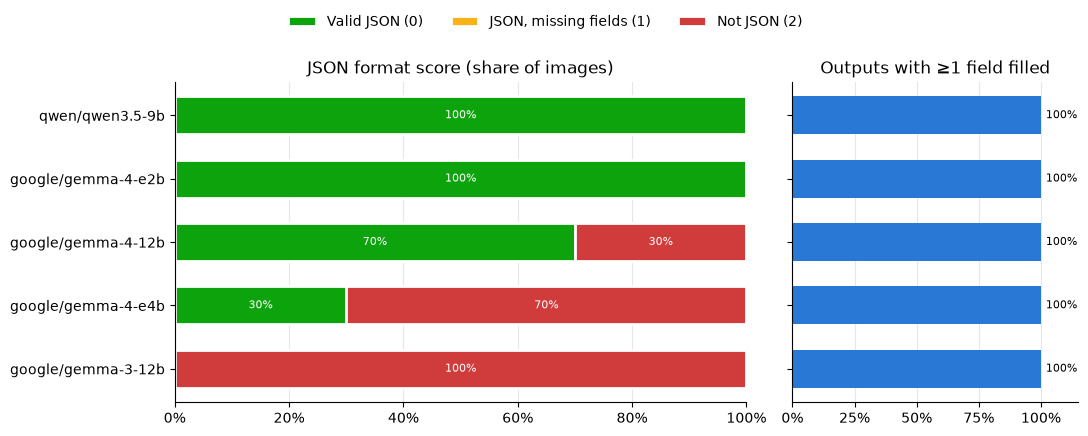

In [125]:
# Forms: JSON format score breakdown + how often any field was actually filled
if KIND == "forms":
    STATUS = [("valid", "Valid JSON (0)", "#0ca30c", "white"),
              ("missing_fields", "JSON, missing fields (1)", "#fab219", "#0b0b0b"),
              ("not_json", "Not JSON (2)", "#d03b3b", "white")]
    s = summary.sort_values(["valid", "filled"]).reset_index(drop=True)    # barh draws bottom-up: best ends on top
    names = s["model"] if len(labels) == 1 else s["model"] + "  ·  " + s["run"]
    y = range(len(s))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 0.5 * len(s) + 1.8), sharey=True,
                                   gridspec_kw={"width_ratios": [2, 1]})
    left = pd.Series(0.0, index=s.index)
    for col, name, color, ink in STATUS:
        ax1.barh(y, s[col] * 100, left=left * 100, height=0.6, color=color,
                 edgecolor="white", linewidth=2, label=name)
        for yi, l, v in zip(y, left, s[col]):
            if v >= 0.1:
                ax1.text((l + v / 2) * 100, yi, f"{v:.0%}", ha="center", va="center", fontsize=8, color=ink)
        left += s[col]
    ax1.set_title("JSON format score (share of images)")

    ax2.barh(y, s["filled"] * 100, height=0.6, color="#2a78d6")
    for yi, v in zip(y, s["filled"]):
        ax2.text(v * 100 + 2, yi, f"{v:.0%}", va="center", fontsize=8)
    ax2.set_title("Outputs with ≥1 field filled")
    ax2.set_xlim(0, 115); ax2.set_xticks(range(0, 101, 25))

    for ax in (ax1, ax2):
        ax.set_yticks(list(y)); ax.set_yticklabels(names)
        ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    ax1.set_xlim(0, 100)
    fig.legend(*ax1.get_legend_handles_labels(), frameon=False, ncol=3,
               loc="upper center", bbox_to_anchor=(0.5, 1.02))
    plt.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

In [126]:
# Forms: pairwise similarity between models' JSON outputs on the same image
import json
from itertools import combinations
from rapidfuzz.distance import Levenshtein

def canonical(text: str) -> str:
    """Strip ```json fences and re-dump valid JSON compactly so formatting doesn't count as a difference."""
    cleaned = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    try:
        return json.dumps(json.loads(cleaned), sort_keys=True, ensure_ascii=False)
    except json.JSONDecodeError:
        return cleaned

if KIND == "forms":
    rows = []
    for (name, label), (d, _, _) in zip(runs, loaded):
        out_dir = RUNS / name / "outputs"
        for image, group in d.groupby("image"):
            files = {m: out_dir / m / (image.replace("img", "out", 1) + ".txt") for m in group["model"]}
            texts = {m: canonical(f.read_text()) for m, f in files.items() if f.exists()}
            for a, b in combinations(sorted(texts), 2):
                rows.append({"run": label, "image": image, "model_a": a, "model_b": b,
                             "similarity_%": Levenshtein.normalized_similarity(texts[a], texts[b]) * 100,
                             "char_diff": Levenshtein.distance(texts[a], texts[b])})
    sim = pd.DataFrame(rows)    # per-image detail
    pair_summary = (sim.groupby(["run", "model_a", "model_b"])[["similarity_%", "char_diff"]]
                       .mean().round(1).sort_values("similarity_%", ascending=False))
    display(pair_summary)

similarity_%  \
run                    model_a            model_b                            
FUNSD_Prompt_Changes_2 google/gemma-3-12b google/gemma-4-12b          42.8   
                       google/gemma-4-12b google/gemma-4-e2b          39.9   
                       google/gemma-3-12b google/gemma-4-e2b          39.1   
                                          qwen/qwen3.5-9b             39.1   
                       google/gemma-4-12b qwen/qwen3.5-9b             35.6   
                       google/gemma-4-e2b google/gemma-4-e4b          34.9   
                                          qwen/qwen3.5-9b             34.3   
                       google/gemma-4-e4b qwen/qwen3.5-9b             31.9   
                       google/gemma-3-12b google/gemma-4-e4b          28.3   
                       google/gemma-4-12b google/gemma-4-e4b          28.1   

                                                              char_diff  
run                    model_a            model_b                        
FUNSD_Prompt_Changes_2 google/gemma-3-12b google/gemma-4-12b      593.9  
                       google/gemma-4-12b google/gemma-4-e2b      557.6  
                       google/gemma-3-12b google/gemma-4-e2b      525.8  
                                          qwen/qwen3.5-9b         553.2  
                       google/gemma-4-12b qwen/qwen3.5-9b         630.4  
                       google/gemma-4-e2b google/gemma-4-e4b      349.0  
                                          qwen/qwen3.5-9b         459.4  
                       google/gemma-4-e4b qwen/qwen3.5-9b         498.1  
                       google/gemma-3-12b google/gemma-4-e4b      607.8  
                       google/gemma-4-12b google/gemma-4-e4b      678.5